# Study Project: Adversarial Machine Learning
## Part I: Statistical Analysis and Generation of Process Data
## Group 15
## SIN Wang Yat

### Task 2: Similarity between Different Datasets

The goal of this task is to analyze the similarity of the provided physical readings between the normal and malicious physical measurements in the dataset WADI 2017. This code satisfies the following requirements:

+ Task 2a Computer the Spearman Distance

  
Compute the Spearman distance of collected physical readings between every two time steps, existing in the dataset WADI_14days and WADI_attackdata and then differentiate between physical readings containing attack and those without attacks.

+ Task 2b Create a Histogram
  
Creates a single histogram plotting the distribution of
the computed Spearman distances for the dataset. The histogram
illustrates the distribution of Spearman distances from both normal and malicious physical measurements of WADI_attackdata


### Libray Import and Data Loading

In [1]:
print(f"Start: Import Library and Load the datasets")
# Library Import
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

# Define the base directory path
base_path = Path.home() / "Projects/P1/data/"
cache_train_file = base_path / "processed/cache_train_file.parquet"
cache_test_file = base_path / "processed/cache_test_file.parquet"

# Load normal 14days data and attack data from CSV or Cache
# Load 14days Dataset
if cache_train_file.exists():
   print("Loading fast cached Parquet data-14days dataset")
   train17_df = pd.read_parquet(cache_train_file)
else:
   print("Cache not found. Load data from CSV file-14days dataset")
   # Skip 4 meta data rows 
   train17_df = pd.read_csv(base_path / "raw/2017/WADI_14days.csv", skiprows=4)
   # Save the cache for next time
   train17_df.to_parquet(cache_train_file)

# Load attackdata Dataset
if cache_test_file.exists():
   print("Loading fast cached Parquet data-attackdata dataset")
   test17_df = pd.read_parquet(cache_test_file)
else:
   print("Cache not found. Load data from CSV file-attackdata dataset")
   test17_df = pd.read_csv(base_path / "raw/2017/WADI_attackdata.csv")
   # Save the cache for next time
   test17_df.to_parquet(cache_test_file)

# Remove the long prefix Column Name 
prefix_to_remove = r"\\WIN-25J4RO10SBF\LOG_DATA\SUTD_WADI\LOG_DATA"

# Replace the string in all column names
train17_df.columns = train17_df.columns.str.replace(prefix_to_remove, "", regex=False)
test17_df.columns = test17_df.columns.str.replace(prefix_to_remove, "", regex=False)

Start: Import Library and Load the datasets
Loading fast cached Parquet data-14days dataset
Loading fast cached Parquet data-attackdata dataset


In [2]:
print(f"Data Shape of WADI_14days")
print(train17_df.shape)

Data Shape of WADI_14days
(1209601, 130)


In [3]:
print(f"Data info of WADI_14days")
print(train17_df.info(verbose=True,show_counts=True))
print(train17_df)

Data info of WADI_14days
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1209601 entries, 0 to 1209600
Data columns (total 130 columns):
 #    Column                     Non-Null Count    Dtype  
---   ------                     --------------    -----  
 0    Row                        1209601 non-null  int64  
 1    Date                       1209601 non-null  object 
 2    Time                       1209601 non-null  object 
 3    \1_AIT_001_PV              1209601 non-null  float64
 4    \1_AIT_002_PV              1209589 non-null  float64
 5    \1_AIT_003_PV              1209601 non-null  float64
 6    \1_AIT_004_PV              1209595 non-null  float64
 7    \1_AIT_005_PV              1209601 non-null  float64
 8    \1_FIT_001_PV              1209601 non-null  float64
 9    \1_LS_001_AL               1209601 non-null  int64  
 10   \1_LS_002_AL               1209601 non-null  int64  
 11   \1_LT_001_PV               1209601 non-null  float64
 12   \1_MV_001_STATUS           12

In [4]:
print(f"Data shape of WADI_attackdata")
print(test17_df.shape)

Data shape of WADI_attackdata
(172801, 130)


In [5]:
print(f"Data info of WADI_attackdata")
print(test17_df.info(verbose=True, show_counts=True))
print(test17_df)

Data info of WADI_attackdata
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 172801 entries, 0 to 172800
Data columns (total 130 columns):
 #    Column                     Non-Null Count   Dtype  
---   ------                     --------------   -----  
 0    Row                        172801 non-null  int64  
 1    Date                       172801 non-null  object 
 2    Time                       172801 non-null  object 
 3    \1_AIT_001_PV              172801 non-null  float64
 4    \1_AIT_002_PV              172801 non-null  float64
 5    \1_AIT_003_PV              172801 non-null  float64
 6    \1_AIT_004_PV              172801 non-null  float64
 7    \1_AIT_005_PV              172801 non-null  float64
 8    \1_FIT_001_PV              172801 non-null  float64
 9    \1_LS_001_AL               172801 non-null  int64  
 10   \1_LS_002_AL               172801 non-null  int64  
 11   \1_LT_001_PV               172801 non-null  float64
 12   \1_MV_001_STATUS           172801 non-nul

### Data Cleaning

In [6]:
print(f"Perform Data Cleaning")
# Remove duplicates (if any)
train17_df.drop_duplicates(inplace=True)
test17_df.drop_duplicates(inplace=True)

Perform Data Cleaning


In [7]:
# Find columns where the count of non-null values is equal to 0
cols_to_drop = train17_df.columns[train17_df.notnull().sum() == 0]

# Drop those columns from the DataFrame
train17_df = train17_df.drop(columns=cols_to_drop)

In [8]:
# Find columns where the count of non-null values is equal to 0
cols_to_drop = test17_df.columns[test17_df.notnull().sum() == 0]

# Drop those columns from the DataFrame
test17_df = test17_df.drop(columns=cols_to_drop)

In [9]:
# Check for null values
pd.set_option('display.max_rows', None)
train17_df.isnull().sum()
pd.reset_option('display.max_rows')

In [10]:
# Check for null values
pd.set_option('display.max_rows', None)
test17_df.isnull().sum()
pd.reset_option('display.max_rows')

In [11]:
# Remove null values 
train17_df = train17_df.ffill().bfill()
test17_df = test17_df.ffill().bfill()


In [12]:
# Check for null values after remoe
train17_df.isnull().sum().sum()
test17_df.isnull().sum().sum()

np.int64(0)

## Classify data columns into Meta Group, Sensor Group or Actuator Group

In [13]:

print(f"Classify the data columns into MetaGroup, Sensor Group and Actuator Group - 14days")
# ==========================================
# EXPLICIT COLUMN GROUPING
# ==========================================
all_cols = train17_df.columns.tolist()

metadata_cols = []
actuator_ctrl_cols = []
sensor_cols = []

for col in all_cols:
    col_upper = col.upper()

    # Identify Metadata columns
    if any(k in col_upper for k in ["ROW", "DATE", "TIME"]):
        metadata_cols.append(col)

    # Identify Continuous Sensor Process Values (_PV and direct flow/pressure metrics)
    elif "_PV" in col_upper or any(
        k in col_upper for k in ["LEAK_DIFF_PRESSURE", "TOTAL_CONS_REQUIRED_FLOW"]
    ):
        sensor_cols.append(col)
        
    # Identify Actuators, Alarms, Controller Outputs, and Setpoints (non-continuous sensors)
    elif any(
        k in col_upper
        for k in [
            "STATUS",
            "_AL",
            "_AH",
            "_CO",
            "_SP",
            "_SPEED",
            "PLANT_START_STOP_LOG",
        ]
    ):
        actuator_ctrl_cols.append(col)

    
    else:
        # Fallback safety: treat anything else as actuator/control if not explicitly a sensor
        actuator_ctrl_cols.append(col)

print(f"\nGroup Breakdown:")
print(f" - Metadata Columns: {len(metadata_cols)}")
print(f" - Actuator Columns: {len(actuator_ctrl_cols)}")
print(f" - Sensor Columns: {len(sensor_cols)}")

Classify the data columns into MetaGroup, Sensor Group and Actuator Group - 14days

Group Breakdown:
 - Metadata Columns: 3
 - Actuator Columns: 77
 - Sensor Columns: 46


In [14]:
print(f"Classify the data columns into MetaGroup, Sensor Group and Actuator Group - attackdata")
# ==========================================
# EXPLICIT COLUMN GROUPING
# ==========================================
tall_cols = test17_df.columns.tolist()

tmetadata_cols = []
tactuator_ctrl_cols = []
tsensor_cols = []

for col in tall_cols:
    col_upper = col.upper()

    # Identify Metadata columns
    if any(k in col_upper for k in ["ROW", "DATE", "TIME"]):
        tmetadata_cols.append(col)

    # Identify Continuous Sensor Process Values (_PV and direct flow/pressure metrics)
    elif "_PV" in col_upper or any(
        k in col_upper for k in ["LEAK_DIFF_PRESSURE", "TOTAL_CONS_REQUIRED_FLOW"]
    ):
        tsensor_cols.append(col)
    
    # Identify Actuators, Alarms, Controller Outputs, and Setpoints (non-continuous sensors)
    elif any(
        k in col_upper
        for k in [
            "STATUS",
            "_AL",
            "_AH",
            "_CO",
            "_SP",
            "_SPEED",
            "PLANT_START_STOP_LOG",
        ]
    ):
        tactuator_ctrl_cols.append(col)

 
    else:
        # Fallback safety: treat anything else as actuator/control if not explicitly a sensor
        tactuator_ctrl_cols.append(col)

print(f"\nGroup Breakdown:")
print(f" - Metadata Columns: {len(tmetadata_cols)}")
print(f" - Actuator Columns: {len(tactuator_ctrl_cols)}")
print(f" - Sensor Columns: {len(tsensor_cols)}")

Classify the data columns into MetaGroup, Sensor Group and Actuator Group - attackdata

Group Breakdown:
 - Metadata Columns: 3
 - Actuator Columns: 77
 - Sensor Columns: 46


## Add new Column Attack Label and Split Attack data from attackdata dataset

In [15]:
print(f"Add Attack Label and classify attack label based on specified time ranges - attackdata")
# Clean column names in case of whitespace artifacts
test17_df.columns = test17_df.columns.str.strip()

# ==========================================
# PARSE TIMESTAMP USING 'Date' AND 'Time' COLUMNS
# ==========================================
# Create a temporary datetime series directly from 'DATE' and 'TIME' 
# without adding a permanent 'DateTime' column to test17_df
temp_datetime = pd.to_datetime(
    test17_df["Date"].astype(str).str.strip() 
    + " " 
    + test17_df["Time"].astype(str).str.strip(),
    format='mixed',
    errors="coerce"
)

# ==========================================
# DEFINE ATTACK TIME RANGES
# ==========================================
attack_ranges = [
    ("09/10/2017 19:25:00", "09/10/2017 19:50:16"),
    ("10/10/2017 10:24:10", "10/10/2017 10:34:00"),
    ("10/10/2017 10:55:00", "10/10/2017 11:24:00"),
    ("10/10/2017 11:07:46", "10/10/2017 11:12:15"),
    ("10/10/2017 11:30:40", "10/10/2017 11:44:50"),
    ("10/10/2017 13:39:30", "10/10/2017 13:50:40"),
    ("10/10/2017 14:48:17", "10/10/2017 14:59:55"),
    ("10/10/2017 14:53:44", "10/10/2017 15:00:32"),
    ("10/10/2017 17:40:00", "10/10/2017 17:49:40"),
    ("11/10/2017 10:55:00", "11/10/2017 10:56:27"),
    ("11/10/2017 11:17:54", "11/10/2017 11:31:20"),
    ("11/10/2017 11:36:31", "11/10/2017 11:47:00"),
    ("11/10/2017 11:59:00", "11/10/2017 12:05:00"),
    ("11/10/2017 12:07:30", "11/10/2017 12:10:52"),
    ("11/10/2017 12:16:00", "11/10/2017 12:25:36"),
    ("11/10/2017 15:26:30", "11/10/2017 15:37:00"),
]

# ==========================================
# INITIALIZE AND POPULATE ATTACK LABELS
# ==========================================
# Initialize attack label column to 1 as default
test17_df["ATTACK_LABEL"] = 1

# Iterate through each attack range and mark matching rows as -1
for start_str, end_str in attack_ranges:
    start_dt = pd.to_datetime(start_str, format="%d/%m/%Y %H:%M:%S")
    end_dt = pd.to_datetime(end_str, format="%d/%m/%Y %H:%M:%S")

    mask = (temp_datetime >= start_dt) & (temp_datetime <= end_dt)
    test17_df.loc[mask, "ATTACK_LABEL"] = -1

# ==========================================
# VERIFICATION
# ==========================================
print("\nLabel distribution summary:")
print(test17_df["ATTACK_LABEL"].value_counts())
print(f"\nFinal DataFrame shape: {test17_df.shape}")
print(f"Last column name: {test17_df.columns[-1]}")

Add Attack Label and classify attack label based on specified time ranges - attackdata

Label distribution summary:
ATTACK_LABEL
 1    162816
-1      9985
Name: count, dtype: int64

Final DataFrame shape: (172801, 127)
Last column name: ATTACK_LABEL


In [16]:
print(f"Data info of attackdata after adding new Attack Label Column")
print(test17_df.info(verbose=True, show_counts=True))
print(test17_df)

Data info of attackdata after adding new Attack Label Column
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 172801 entries, 0 to 172800
Data columns (total 127 columns):
 #    Column                     Non-Null Count   Dtype  
---   ------                     --------------   -----  
 0    Row                        172801 non-null  int64  
 1    Date                       172801 non-null  object 
 2    Time                       172801 non-null  object 
 3    \1_AIT_001_PV              172801 non-null  float64
 4    \1_AIT_002_PV              172801 non-null  float64
 5    \1_AIT_003_PV              172801 non-null  float64
 6    \1_AIT_004_PV              172801 non-null  float64
 7    \1_AIT_005_PV              172801 non-null  float64
 8    \1_FIT_001_PV              172801 non-null  float64
 9    \1_LS_001_AL               172801 non-null  int64  
 10   \1_LS_002_AL               172801 non-null  int64  
 11   \1_LT_001_PV               172801 non-null  float64
 12   \1_MV_001

In [17]:
print(f"Separate the attackdata into 2 datasets: 1 with normal data and 1 with attack data")
# ==========================================
# SEPARATE DATASET BY ATTACK LABEL
# ==========================================

# Filter rows where ATTACK_LABEL is 1 (Normal data)
test17_normal_df = test17_df[test17_df["ATTACK_LABEL"] == 1].copy()

# Filter rows where ATTACK_LABEL is -1 (Attack data)
test17_attack_df = test17_df[test17_df["ATTACK_LABEL"] == -1].copy()

# ==========================================
# VERIFICATION
# ==========================================
print(f"Original DataFrame shape: {test17_df.shape}")
print(f"Normal DataFrame shape (`test17_normal_df`): {test17_normal_df.shape}")
print(f"Attack DataFrame shape (`test17_attack_df`): {test17_attack_df.shape}")

Separate the attackdata into 2 datasets: 1 with normal data and 1 with attack data
Original DataFrame shape: (172801, 127)
Normal DataFrame shape (`test17_normal_df`): (162816, 127)
Attack DataFrame shape (`test17_attack_df`): (9985, 127)


 ## Task 2a Compute Spearman Distance

In [18]:
print(f"Task 2a Compute Spearman Distance")
# ==========================================
# PREPARE THE THREE DIFFERENTIATED DATASETS
# ==========================================
# Dataset 1: Baseline Normal (train17_df)
df_train_sensors = train17_df[sensor_cols].ffill().bfill().fillna(0)

# Dataset 2: Test Data WITHOUT Attacks (test17_normal_df)
df_test_normal_sensors = test17_normal_df[sensor_cols].ffill().bfill().fillna(0)

# Dataset 3: Test Data CONTAINING Attacks (test17_attack_df)
df_test_attack_sensors = test17_attack_df[sensor_cols].ffill().bfill().fillna(0)


# ==========================================
# CUSTOM SPEARMAN IMPLEMENTATION (FROM SCRATCH)
# ==========================================
def compute_rank(arr):
    """Computes average ranks for ties (equivalent to scipy.stats.rankdata)."""
    sort_idx = np.argsort(arr)
    rank = np.empty_like(sort_idx, dtype=float)
    n = len(arr)
    i = 0
    while i < n:
        j = i
        while j < n - 1 and arr[sort_idx[j]] == arr[sort_idx[j + 1]]:
            j += 1
        # Assign average rank for tied values
        avg_rank = (i + j) / 2.0 + 1
        for k in range(i, j + 1):
            rank[sort_idx[k]] = avg_rank
        i = j + 1
    return rank


def custom_spearman_correlation_matrix(df):
    """Computes the Spearman rank correlation matrix for all columns 

    in a DataFrame from scratch using only NumPy.
    """
    data = df.to_numpy()
    n_rows, n_cols = data.shape
    
    # Step 1: Convert each column to its ranks
    ranked_data = np.empty_like(data, dtype=float)
    for j in range(n_cols):
        ranked_data[:, j] = compute_rank(data[:, j])
        
    # Step 2: Compute Pearson correlation on the ranked data
    # Mean-center the ranks
    means = np.mean(ranked_data, axis=0)
    centered = ranked_data - means
    
    # Numerator: Covariance matrix of ranks
    cov_matrix = np.dot(centered.T, centered) / (n_rows - 1)
    
    # Denominator: Standard deviations of ranks
    std_devs = np.std(ranked_data, axis=0, ddof=1)
    outer_std = np.outer(std_devs, std_devs)
    
    # Avoid division by zero for constant columns
    outer_std[outer_std == 0] = 1.0
    
    spearman_corr = cov_matrix / outer_std
    # Clip to handle minor floating-point inaccuracies outside [-1, 1]
    spearman_corr = np.clip(spearman_corr, -1.0, 1.0)
    
    return spearman_corr


# ==========================================
# COMPUTE SPEARMAN DISTANCE MATRICES
# ==========================================
print("\nComputing Spearman correlation and distance matrices")
print(" - Processing Baseline Normal (train17_df-WADI_14days)...")
corr_train = custom_spearman_correlation_matrix(df_train_sensors)

print(" - Processing Test Normal (test17_normal_df-WADI_attackdata)...")
corr_test_normal = custom_spearman_correlation_matrix(df_test_normal_sensors)

print(" - Processing Test Attack (test17_attack_df-WADI_attackdata)...")
corr_test_attack = custom_spearman_correlation_matrix(df_test_attack_sensors)

# Spearman Distance is defined as: Distance = 1 - Correlation
dist_train = 1.0 - corr_train
dist_test_normal = 1.0 - corr_test_normal
dist_test_attack = 1.0 - corr_test_attack


# ==========================================
# SUMMARIZE & COMPARE DISTANCE STRUCTURES
# ==========================================
print("\n" + "=" * 50)
print("TASK 2a: SPEARMAN DISTANCE ANALYSIS SUMMARY")
print("=" * 50)
print(f"Average Spearman Distance (Baseline Normal-WADI_14days):    {np.mean(dist_train):.4f}")
print(f"Average Spearman Distance (Test Normal-WADI_attackdata):    {np.mean(dist_test_normal):.4f}")
print(f"Average Spearman Distance (Test Attack-WADI_attackdata):    {np.mean(dist_test_attack):.4f}")

Task 2a Compute Spearman Distance

Computing Spearman correlation and distance matrices
 - Processing Baseline Normal (train17_df-WADI_14days)...
 - Processing Test Normal (test17_normal_df-WADI_attackdata)...
 - Processing Test Attack (test17_attack_df-WADI_attackdata)...

TASK 2a: SPEARMAN DISTANCE ANALYSIS SUMMARY
Average Spearman Distance (Baseline Normal-WADI_14days):    0.9650
Average Spearman Distance (Test Normal-WADI_attackdata):    0.9687
Average Spearman Distance (Test Attack-WADI_attackdata):    0.9612


## Task 2b Create a Histogram

Task 2b Create Historgram


<function matplotlib.pyplot.close(fig: "None | int | str | Figure | Literal['all']" = None) -> 'None'>

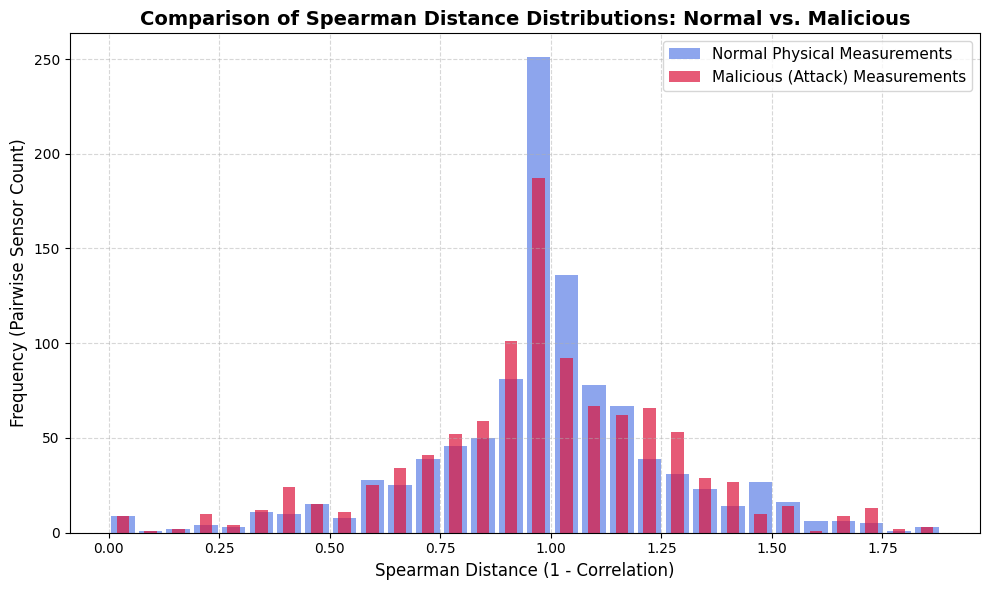

In [19]:
print(f"Task 2b Create Historgram")

# ==========================================
# EXTRACT PAIRWISE SPEARMAN DISTANCES
# ==========================================
# Extract off-diagonal elements from the distance matrices to avoid self-correlations (diagonal = 0)
n_sensors = corr_test_normal.shape[0]
triu_indices = np.triu_indices(n_sensors, k=1)

normal_distances = (1.0 - corr_test_normal)[triu_indices]
attack_distances = (1.0 - corr_test_attack)[triu_indices]

# ==========================================
# HISTOGRAM COMPUTATION 
# ==========================================
n_bins = 30
combined_data = np.concatenate([normal_distances, attack_distances])
min_val, max_val = np.min(combined_data), np.max(combined_data)

# Avoid division by zero if all values are identical
if min_val == max_val:
    max_val += 1e-5

bin_width = (max_val - min_val) / n_bins
bin_edges = [min_val + (i * bin_width) for i in range(n_bins + 1)]

def compute_manual_histogram(data, edges, width):
    """Computes bin frequencies manually using basic logic without libraries."""
    n_b = len(edges) - 1
    counts = [0] * n_b
    for val in data:
        # Determine the bin index mathematically
        idx = int((val - edges[0]) / width)
        if idx >= n_b:
            idx = n_b - 1
        elif idx < 0:
            idx = 0
        counts[idx] += 1
    return counts

# Compute frequencies for both distributions
normal_counts = compute_manual_histogram(normal_distances, bin_edges, bin_width)
attack_counts = compute_manual_histogram(attack_distances, bin_edges, bin_width)

# Calculate bin centers for rendering bars
bin_centers = [(bin_edges[i] + bin_edges[i + 1]) / 2.0 for i in range(n_bins)]

# ==========================================
# PLOT AND DISPLAY THE SINGLE HISTOGRAM
# ==========================================
plt.figure(figsize=(10, 6))

# Plot normal and malicious distributions on the same axes with transparency
plt.bar(
    bin_centers, 
    normal_counts, 
    width=bin_width * 0.85, 
    alpha=0.6, 
    color='royalblue', 
    label='Normal Physical Measurements'
)
plt.bar(
    bin_centers, 
    attack_counts, 
    width=bin_width * 0.45, 
    alpha=0.7, 
    color='crimson', 
    label='Malicious (Attack) Measurements'
)

plt.xlabel('Spearman Distance (1 - Correlation)', fontsize=12)
plt.ylabel('Frequency (Pairwise Sensor Count)', fontsize=12)
plt.title('Comparison of Spearman Distance Distributions: Normal vs. Malicious', fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

# Display the plot
plt.savefig('T2_historgam.png')
plt.close